In [3]:
import wandb
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

In [59]:
api = wandb.Api(api_key='4a3e44e53460799e4aae1531c4bdfbd4e22f82ce')
path = 'kprotopapas/rl_experiments'
alg = 'deqa'
metric = 'suboptimality'
inexact = False
n = 5
limit = 90
runs = api.runs(path=path, filters={'group': f'{alg}_v1_exact'})
dfs = {d: [] for d in [1, 5, 10, 15, 20]}

In [51]:
cutoff = 5 if inexact else 4
for run in runs:
    temp = run.history(keys=[metric], x_axis='_step')\
        .rename(columns={'_step': 'k', metric: f'{metric}_{run.id}'})
    
    if len(temp) > 80:    
        temp = temp.set_index('k')
        depth = int(run.config['algorithm'][:-cutoff])
        dfs[depth].append(temp)
    

In [61]:
n = 5

In [104]:
dfs_small = {k: v[5:] for k, v in dfs.items()}
joined = {k: pd.concat(v, axis=1) for k, v in dfs_small.items()}
stds = {k: v.std(axis=1).rename(f'{k}-std') for k, v in joined.items()}
means = {k: v.mean(axis=1).rename(f'{k}-mean') for k, v in joined.items()}

In [54]:
# means_df = pd.concat(means.values(), axis=1).iloc[:limit]
# stds_df = pd.concat(stds.values(), axis=1).iloc[:limit]
# means_df = means_df - means_df.min()

In [105]:
means_df_other = pd.concat(means.values(), axis=1).iloc[:limit]
stds_df_other = pd.concat(stds.values(), axis=1).iloc[:limit]
means_df_other = means_df_other - means_df_other.min()

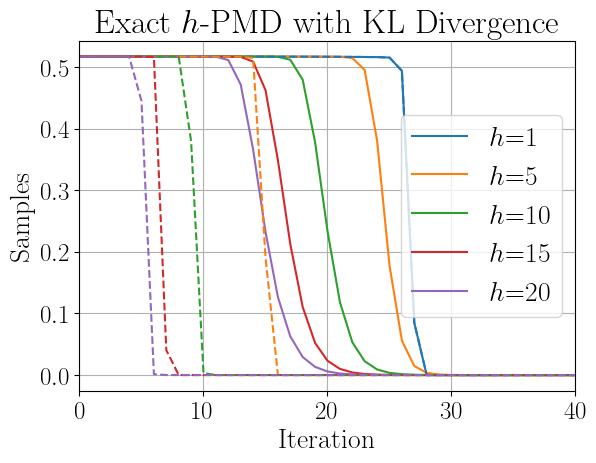

In [108]:
import matplotlib.pyplot as plt
# choose a large font size by default and use tex for math
fontsize = 18
params = {'axes.labelsize': fontsize + 2,
      'font.size': fontsize + 2,
      'legend.fontsize': fontsize + 2,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'text.usetex': True}
plt.rcParams.update(params)
plt.rc('font', family='Times New Roman')
fig, ax = plt.subplots()
ax.plot(means_df)
plt.gca().set_prop_cycle(None)
ax.plot(means_df_other, linestyle='dashed')
for name, std in stds_df.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = means_df[mean_name]
    mean_other = means_df_other[mean_name]
    std_other = stds_df_other[name]
    ax.fill_between(std.index, mean - std, mean + std, alpha=0.2)
    ax.fill_between(std_other.index, mean_other - std_other, mean_other + std_other, alpha=0.2)


ax.grid(visible=True)
ax.set_xlabel('Iteration')
ax.set_ylabel('Samples')
ax.set_xlim(0, 40)
legends = [f'$h$={depth}' for depth in [1, 5, 10, 15, 20]]
ax.legend(legends)
ax.set_title('Exact $h$-PMD with KL Divergence')
plt.subplots_adjust(bottom=0.15)
plt.savefig(f'{alg}_exact.pdf')